In [ ]:
from pathlib import Path
 
import pandas as pd
 
from dataset import prepare_client_data, TARGET, DROP_COLS

 
# ============================================================
# 1. KONFIGURASI
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
 
# ============================================================
# 2. MUAT DATA SEMUA CLIENT (scaling + konversi ke tensor)
# ============================================================
clients, scaler, feature_names = prepare_client_data(CLIENT_DIR)
 
print(f"Jumlah client : {len(clients)}")
print(f"Daftar state  : {list(clients.keys())}")
print(f"Target        : {TARGET}")
print(f"Kolom dibuang : {DROP_COLS}")
 
# ============================================================
# 3. DAFTAR FITUR YANG DIPAKAI
# ============================================================
n_fitur = next(iter(clients.values()))['X_train_t'].shape[1]
assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
 
print(f"\nJumlah fitur  : {n_fitur}")
for i, nama in enumerate(feature_names, 1):
    print(f"{i:>3}. {nama}")
 
# ============================================================
# 4. RINGKASAN TIAP CLIENT
# ============================================================
rows = {}
for st, c in clients.items():
    rows[st] = {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    }
 
ringkas = pd.DataFrame(rows).T
ringkas.index.name = 'state'
 
for s in ('train', 'val', 'test'):
    ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
 
total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
for s in ('train', 'val', 'test'):
    total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
ringkas.loc['TOTAL'] = total
 
print("\nRingkasan per client:")
print(ringkas.to_string())
 
# %%
# ============================================================
# 5. KONVERSI clients -> fed_data (format yang diminta fl_runner)
# ============================================================
fed_data = {}
for st, c in clients.items():
    fed_data[f"state_{st}"] = {
        "X_train": c["X_train_t"], "y_train": c["y_train_t"],
        "X_val":   c["X_val_t"],   "y_val":   c["y_val_t"],
        "X_test":  c["X_test_t"],  "y_test":  c["y_test_t"],
        "n_features": c["X_train_t"].shape[1],
    }
 
print("Client:", list(fed_data.keys()))
print("n_features per client:", {k: v["n_features"] for k, v in fed_data.items()})

Jumlah client : 44
Daftar state  : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target        : _michd
Kolom dibuang : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']

Jumlah fitur  : 69
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnkany6
 32. flushot7
 33. pneuvac4
 34. marital_1
 35. marital_2
 36. marital_3
 37. marital_4
 38. marital_5
 39. marital_6
 40. employ1_1
 41. employ1_2
 42. employ1_3
 43. employ1_4
 44. employ1_5
 45. employ1_6
 46. employ1_7
 47. employ1_8
 48. renthom1_1
 49. renthom1_2
 50. 

2026-10-20 03:05:13,640	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
INFO :      Starting Flower ServerApp, config: num_rounds=2, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Evaluating initial global parameters
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 44 clients (out of 44)
INFO :      aggregate_fit: received 44 results and 0 failures
INFO :      fit progress: (1, 0.5968471496558886, {'accuracy': 0.7822180254001545, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'auc': 0.5787996846747117}, 10.292153100017458)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 44 clients (out of 44)


[smoke|sim|fedavg] round 01 | loss=0.5968 acc=0.7822 prec=0.0000 rec=0.0000 f1=0.0000 auc=0.5788 | comm=2.095MB (cum 2.095MB)


INFO :      aggregate_fit: received 44 results and 0 failures
INFO :      fit progress: (2, 0.5310580843595075, {'accuracy': 0.7822180254001545, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'auc': 0.6740515006665855}, 12.540752000000793)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 2 round(s) in 12.54s
INFO :      	History (loss, centralized):
INFO :      		round 1: 0.5968471496558886
INFO :      		round 2: 0.5310580843595075
INFO :      	History (metrics, distributed, fit):
INFO :      	{'bytes_down': [(1, 1098240.0), (2, 1098240.0)],
INFO :      	 'bytes_up': [(1, 1098240.0), (2, 1098240.0)]}
INFO :      	History (metrics, centralized):
INFO :      	{'accuracy': [(1, 0.7822180254001545), (2, 0.7822180254001545)],
INFO :      	 'auc': [(1, 0.5787996846747117), (2, 0.6740515006665855)],
INFO :      	 'f1': [(1, 0.0), (2, 0.0)],
INFO :      	 'precision': [(1, 0.0), (2, 0.0)],
INFO :      	 'recall': 

[smoke|sim|fedavg] round 02 | loss=0.5311 acc=0.7822 prec=0.0000 rec=0.0000 f1=0.0000 auc=0.6741 | comm=2.095MB (cum 4.189MB)
[smoke|sim|fedavg] best val round (by f1) = 1
[0.0, 0.0] {'theta_size_mb': 0.0238037109375, 'total_up_mb': 2.0947265625, 'total_down_mb': 2.0947265625, 'total_mb': 4.189453125, 'avg_per_round_mb': 2.0947265625, 'avg_per_client_mb': 0.09521484375, 'full_total_mb': 7.2415771484375, 'saving_pct': 42.147227888002966}


INFO :      Starting Flower ServerApp, config: num_rounds=10, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Evaluating initial global parameters
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 44 clients (out of 44)
INFO :      aggregate_fit: received 44 results and 0 failures
INFO :      fit progress: (1, 0.5328269889292768, {'accuracy': 0.7824977826755662, 'precision': 0.19061598124098122, 'recall': 0.009337337783428367, 'f1': 0.015694989587490105, 'auc': 0.6926094358593412}, 8.282945399987511)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 44 clients (out of 44)


...

[cmp|alt|pairwise] round 09 | loss=3.1908 acc=0.7258 prec=0.3569 rec=0.3245 f1=0.3383 auc=0.6405 | comm=2.095MB (cum 18.853MB)


INFO :      aggregate_fit: received 44 results and 0 failures
INFO :      fit progress: (10, 3.629441098278347, {'accuracy': 0.7252411367802183, 'precision': 0.35748079430804813, 'recall': 0.3287181150813248, 'f1': 0.34083542429783065, 'auc': 0.6395209919862096}, 38.63997010001913)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 10 round(s) in 38.64s
INFO :      	History (loss, centralized):
INFO :      		round 1: 0.524142681064117
INFO :      		round 2: 0.5291622306917962
INFO :      		round 3: 0.605485041805244
INFO :      		round 4: 0.7601849421496746
INFO :      		round 5: 1.0302096957399307
INFO :      		round 6: 1.456820668971133
INFO :      		round 7: 2.0063495355376983
INFO :      		round 8: 2.6047983358493236
INFO :      		round 9: 3.19076857696132
INFO :      		round 10: 3.629441098278347
INFO :      	History (metrics, distributed, fit):
INFO :      	{'agg_weight_client_0': [(1, 0.03519503910

[cmp|alt|pairwise] round 10 | loss=3.6294 acc=0.7252 prec=0.3575 rec=0.3287 f1=0.3408 auc=0.6395 | comm=2.095MB (cum 20.947MB)


INFO :      	 'agg_weight_client_35': [(1, 0.025963000241930382),
INFO :      	                          (2, 0.0267093676592437),
INFO :      	                          (3, 0.024267275742275093),
INFO :      	                          (4, 0.026664510413204254),
INFO :      	                          (5, 0.026877424247343278),
INFO :      	                          (6, 0.020211285740961635),
INFO :      	                          (7, 0.025395265419145392),
INFO :      	                          (8, 0.019853196743622608),
INFO :      	                          (9, 0.027479599014164004),
INFO :      	                          (10, 0.02580120466841656)],
INFO :      	 'agg_weight_client_36': [(1, 0.03731803195845903),
INFO :      	                          (2, 0.02065102869229553),
INFO :      	                          (3, 0.023880513026695367),
INFO :      	                          (4, 0.02529250824858189),
INFO :      	                          (5, 0.020345585951419717),
INFO :      	 

[cmp|alt|pairwise] best val round (by f1) = 2

               val_f1_last  best_round  test_acc  test_prec  test_rec  test_f1  test_auc  testbest_f1  total_MB
config                                                                                                        
sim+fedavg         0.3311           4    0.7347     0.3441    0.3051   0.3198    0.6399       0.3614   20.9473
sim+fedprox        0.3322           3    0.7362     0.3467    0.3054   0.3214    0.6429       0.3812   20.9473
sim+pairwise       0.3269           3    0.7390     0.3448    0.2875   0.3104    0.6419       0.3709   20.9473
alt+fedavg         0.3449           2    0.7255     0.3353    0.3322   0.3316    0.6434       0.4203   20.9473
alt+fedprox        0.3404           2    0.7272     0.3357    0.3280   0.3296    0.6435       0.4188   20.9473
alt+pairwise       0.3450           2    0.7274     0.3363    0.3281   0.3298    0.6393       0.4304   20.9473

######## sim : ronde terbaik (val) ########

client            

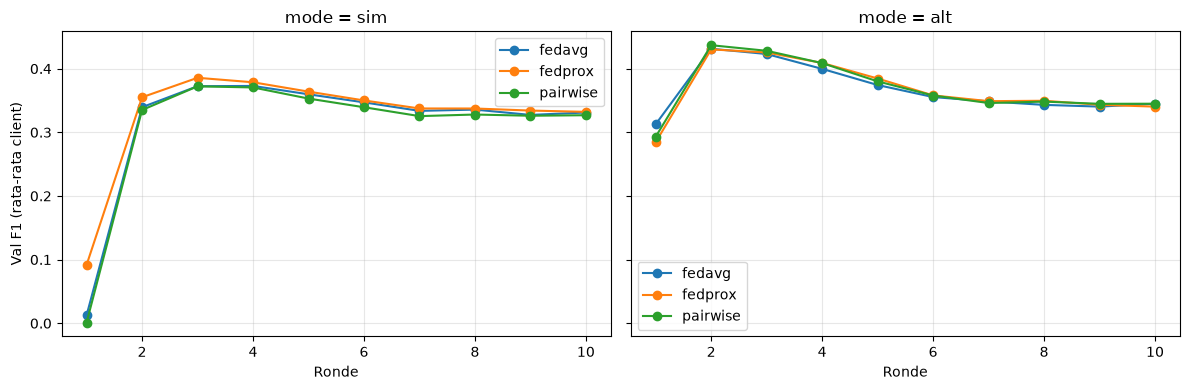

In [2]:
# ============================================================
# 6. IMPORT RUNNER
#    fl_runner.py, model.py, aggregation4.py harus satu folder
#    dengan script ini (atau ada di sys.path).
# ============================================================
import importlib
import fl_running1
importlib.reload(fl_running1)            # supaya perubahan file langsung terbaca
from fl_running1 import (
    run_federated, run_comparison,
    print_comparison, print_seed_summary,
    export_history_csv, export_per_client_csv,
    export_comparison_csv, export_rounds_comparison_csv,
)
 
COMMON_DIM = 64      # dimensi bersama untuk theta, sesuaikan dengan build_model
N_CLASSES  = 2
 
# %%
# ============================================================
# 7. TES CEPAT (sanity check): 2 ronde, 1 epoch
# ============================================================
h_test = run_federated(
    fed_data, name="smoke",
    common_dim=COMMON_DIM, n_classes=N_CLASSES,
    num_rounds=2, local_epochs=1,
    mode="sim", aggregation="fedavg",
    verbose_report=False,
)
print(h_test["f1"], h_test["comm"])
 
# %%
# ============================================================
# 8. JALANKAN SATU KONFIGURASI PENUH (laporan lengkap)
# ============================================================
history = run_federated(
    fed_data, name="exp",
    common_dim=COMMON_DIM, n_classes=N_CLASSES,
    num_rounds=10, local_epochs=5, batch_size=64, lr=1e-3,
    mode="alt", aggregation="pairwise",
    epochs_v=3, epochs_u=2,
    select_by="f1",
    verbose_report=True,
)
 
print("\nTEST ronde terakhir (rata-rata client):", history["test"])
print("TEST ronde terbaik  (rata-rata client):", history.get("test_best"),
      "| best_round =", history.get("best_round"))
 
# %%
# ============================================================
# 9. BANDINGKAN mode x aggregation (fedavg vs fedprox vs pairwise)
#    seeds > 1 -> hasil dirata-rata (mean ± std)
# ============================================================
NUM_ROUNDS   = 10
LOCAL_EPOCHS = 5
SEEDS        = (42,22,1)          # contoh: (0, 1, 2)
AGGS         = ("fedavg", "fedprox", "pairwise")
 
all_hist = {}                 # {"sim": {agg: history}, "alt": {...}}
for mode in ("sim", "alt"):
    print(f"\n################ MODE: {mode} ################")
    all_hist[mode] = run_comparison(
        fed_data, name="cmp", common_dim=COMMON_DIM,
        aggregations=AGGS, seeds=SEEDS,
        n_classes=N_CLASSES,
        num_rounds=NUM_ROUNDS, local_epochs=LOCAL_EPOCHS,
        mode=mode, fedprox_mu=0.01,
        select_by="f1",
    )
 
# Tabel ringkasan (satu baris per mode+agregasi)
rows = []
for mode, hs in all_hist.items():
    for agg, h in hs.items():
        t  = h.get("test") or {}
        tb = h.get("test_best") or {}
        rows.append({
            "config":       f"{mode}+{agg}",
            "val_f1_last":  h["f1"][-1] if h["f1"] else None,
            "best_round":   h.get("best_round"),
            "test_acc":     t.get("accuracy"),
            "test_prec":    t.get("precision"),
            "test_rec":     t.get("recall"),
            "test_f1":      t.get("f1"),
            "test_auc":     t.get("auc"),
            "testbest_f1":  tb.get("f1"),
            "total_MB":     h["comm"]["total_mb"],
        })
summary = pd.DataFrame(rows).set_index("config").round(4)
print("\n", summary.to_string())
 
# %%
# ============================================================
# 10. DETAIL KOMPARASI PER CLIENT (per mode)
# ============================================================
for mode, hs in all_hist.items():
    print(f"\n######## {mode} : ronde terbaik (val) ########")
    print_comparison(hs, split="test_best_per_client", baseline="fedavg")
    if len(SEEDS) > 1:
        print_seed_summary(hs, split="test_best")
 
# %%
# ============================================================
# 11. EKSPOR CSV
# ============================================================
OUT_DIR = Path("hasil_fl"); OUT_DIR.mkdir(exist_ok=True)
 
for mode, hs in all_hist.items():
    for agg, h in hs.items():
        tag = f"{mode}_{agg}"
        export_history_csv(h, str(OUT_DIR / f"{tag}_rounds.csv"))
        export_per_client_csv(h, str(OUT_DIR / f"{tag}_per_client_val.csv"))
        export_per_client_csv(h, str(OUT_DIR / f"{tag}_per_client_test.csv"),
                              split="test_per_client")
    export_comparison_csv(hs, str(OUT_DIR / f"{mode}_compare_test_best.csv"),
                          split="test_best_per_client")
    export_rounds_comparison_csv(hs, str(OUT_DIR / f"{mode}_compare_rounds.csv"))
summary.to_csv(OUT_DIR / "summary.csv")
 
# %%
# ============================================================
# 12. PLOT KURVA F1 PER RONDE
# ============================================================
import matplotlib.pyplot as plt
 
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (mode, hs) in zip(axes, all_hist.items()):
    for agg, h in hs.items():
        ax.plot(h["round"], h["f1"], marker="o", label=agg)
    ax.set_title(f"mode = {mode}")
    ax.set_xlabel("Ronde")
    ax.grid(alpha=.3)
    ax.legend()
axes[0].set_ylabel("Val F1 (rata-rata client)")
plt.tight_layout()
plt.savefig(OUT_DIR / "f1_per_round.png", dpi=150)
plt.show()